# RavenStack | Customer Churn & Retention Analysis

**Python exploratory analysis**  
**Audience:** Customer Success & Retention  
**Source:** SQL Server — `analytics.vw_account_360`

This notebook studies historical churn labels and their association with customer segments, subscription behavior, product engagement, and support experience. The source dataset is synthetic. Findings are descriptive, not causal.

**Metric definition:** `churn_flag = 1` identifies accounts flagged as **ever churned**. It does not measure current customer status or monthly churn.

## 1. Connect and load

The database is the source of truth. SQL handles relationship integrity and account-level aggregation; Python handles exploration and visualizations. Set `SERVER` to your SQL Server instance name. Windows authentication is used below.

In [41]:
# pip install pandas matplotlib seaborn sqlalchemy pyodbc 

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

server = r"DESKTOP-B94VOMQ\SQLEXPRESS"
database = "RavenStack_Churn"

connection_url = URL.create(
    "mssql+pyodbc",
    host=server,
    database=database,
    query={
        "driver": "ODBC Driver 17 for SQL Server",
        "trusted_connection": "yes",
    },
)

engine = create_engine(connection_url)

df = pd.read_sql("SELECT * FROM analytics.vw_account_360", engine)

df.head()

,account_id,account_name,industry,country,signup_date,referral_source,plan_tier,seats,is_trial,churn_flag,...,tickets_before_signup_count,response_after_closure_count,escalation_count,avg_valid_satisfaction,avg_valid_resolution_hours,event_count,churn_event_count,reactivation_event_count,first_churn_event_date,recorded_refund_sum
0,A-00bed1,Company_306,Cybersecurity,US,2023-11-14,ads,Basic,28,True,False,...,1,0,0,4.0,20.333333,1,1,0,2024-01-03,21.17
1,A-00cac8,Company_26,HealthTech,AU,2023-09-15,organic,Enterprise,8,True,False,...,1,1,0,NaN,NaN,0,0,0,None,0.00
2,A-0158bb,Company_461,FinTech,DE,2024-05-22,partner,Basic,5,False,False,...,1,0,0,NaN,NaN,0,0,0,None,0.00
3,A-016043,Company_405,EdTech,CA,2024-07-31,organic,Basic,4,True,False,...,2,0,0,NaN,59.000000,1,1,0,2024-08-11,84.75
4,A-019782,Company_142,DevTools,FR,2023-04-19,event,Enterprise,11,False,False,...,0,0,0,3.0,10.000000,0,0,0,None,0.00


## 2. Validate the analytical dataset

The SQL validation already reconciled source and view totals. Here we check the account grain and essential columns before working with the data.

In [43]:
required_columns = {
    "account_id", "churn_flag", "industry", "plan_tier", "seats",
    "subscription_count", "recorded_mrr_sum", "upgrade_count", "downgrade_count",
    "usage_record_count", "valid_usage_record_count", "recorded_usage_count",
    "valid_usage_count", "usage_before_signup_count",
    "usage_outside_subscription_count", "ticket_count",
    "tickets_before_signup_count", "avg_valid_satisfaction",
    "avg_valid_resolution_hours", "event_count", "churn_event_count"
}

missing_columns = required_columns - set(df.columns)

assert not missing_columns, f"Missing columns: {sorted(missing_columns)}"
assert df["account_id"].is_unique, "Duplicate account IDs found"
assert df["account_id"].notna().all(), "Missing account IDs found"
assert df["churn_flag"].notna().all(), "Missing churn flags found"
assert df["churn_flag"].isin([0, 1]).all(), "Invalid churn labels found"

print("Dataset shape:", df.shape)
print("Unique accounts:", df["account_id"].nunique())

missing_values = df.isna().sum()
display(missing_values[missing_values > 0])

Dataset shape: (500, 36)
Unique accounts: 500


last_valid_usage_date          31
avg_valid_satisfaction        194
avg_valid_resolution_hours    132
first_churn_event_date        161
dtype: int64

## 3. Churn overview

The proportion below is an **ever-churned account share**. Never interpret it as a monthly churn or retention rate.

In [44]:
total_accounts = len(df)
churned_accounts = df["churn_flag"].sum()
churn_percentage = churned_accounts / total_accounts * 100

print(f"Total Accounts: {total_accounts:,}")
print(f"Ever-Churned Accounts: {churned_accounts:,}")
print(f"Ever-Churned Percentage: {churn_percentage:.2f}%")

Total Accounts: 500
Ever-Churned Accounts: 110
Ever-Churned Percentage: 22.00%


## 4. Customer Segmentation

Compare the percentage of ever-churned accounts across industries,
subscription plans, and account sizes.

Segment sizes are considered alongside churn percentages to avoid
misleading comparisons.

In [45]:
def segment_summary(column):
    summary = (
        df.groupby(column)
        .agg(
            total_accounts=("account_id", "count"),
            churned_accounts=("churn_flag", "sum"),
            churn_percentage=("churn_flag", "mean")
        )
        .reset_index()
    )

    summary["churn_percentage"] = (
        summary["churn_percentage"] * 100
    ).round(2)

    return summary.sort_values("churn_percentage", ascending=False)


industry_summary = segment_summary("industry")
plan_summary = segment_summary("plan_tier")

display(industry_summary)
display(plan_summary)

,industry,total_accounts,churned_accounts,churn_percentage
1,DevTools,113,35,30.97
3,FinTech,112,25,22.32
4,HealthTech,96,21,21.88
2,EdTech,79,13,16.46
0,Cybersecurity,100,16,16.00


,plan_tier,total_accounts,churned_accounts,churn_percentage
1,Enterprise,154,34,22.08
0,Basic,168,37,22.02
2,Pro,178,39,21.91


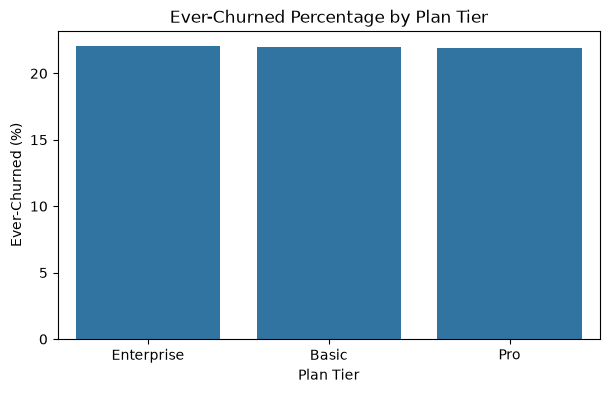

In [46]:
plt.figure(figsize=(7, 4))

sns.barplot(
    data=plan_summary,
    x="plan_tier",
    y="churn_percentage"
)

plt.title("Ever-Churned Percentage by Plan Tier")
plt.xlabel("Plan Tier")
plt.ylabel("Ever-Churned (%)")

plt.show()

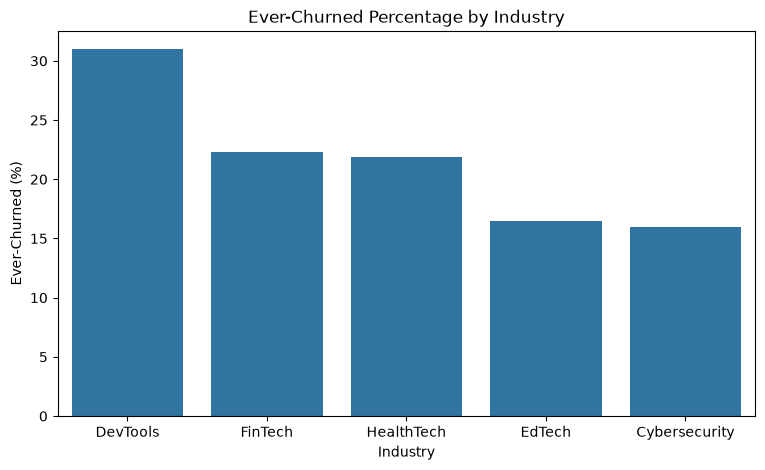

In [47]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=industry_summary,
    x="industry",
    y="churn_percentage"
)

plt.title("Ever-Churned Percentage by Industry")
plt.xlabel("Industry")
plt.ylabel("Ever-Churned (%)")

plt.show()

**Observation:** DevTools has the highest ever-churned percentage (30.97%), while Cybersecurity has the lowest (16.00%). In contrast, subscription plans show very similar percentages across all tiers (approximately 22%).

Industry appears to be a more useful segmentation dimension to explore than plan tier, although these comparisons do not establish causation.

### Account Size Analysis
Group accounts into seat-count bands to compare ever-churned percentages across customer sizes. These bands are analytical choices, not official company segments.

In [48]:
df["seat_band"] = pd.cut(
    df["seats"],
    bins=[0, 5, 10, 25, 50, float("inf")],
    labels=["1-5", "6-10", "11-25", "26-50", "51+"]
)

seat_summary = segment_summary("seat_band")
display(seat_summary)

,seat_band,total_accounts,churned_accounts,churn_percentage
1,6-10,72,21,29.17
3,26-50,106,23,21.70
4,51+,37,8,21.62
0,1-5,126,26,20.63
2,11-25,159,32,20.13


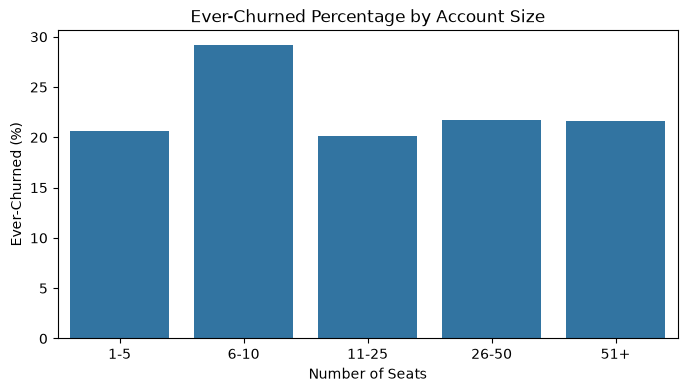

In [49]:
plt.figure(figsize=(8, 4))

sns.barplot(
    data=seat_summary,
    x="seat_band",
    y="churn_percentage"
)

plt.title("Ever-Churned Percentage by Account Size")
plt.xlabel("Number of Seats")
plt.ylabel("Ever-Churned (%)")
plt.show()

## 5. Subscription behavior

Amounts in `recorded_mrr_sum` aggregate historical subscription records. They are **not current company MRR**.
 
Upgrade/downgrade counts refer to flagged subscription records, not unique customer transitions.

In [50]:
subscription_summary = (
    df.groupby("churn_flag")
    .agg(
        accounts=("account_id", "count"),
        avg_subscriptions=("subscription_count", "mean"),
        avg_upgrades=("upgrade_count", "mean"),
        avg_downgrades=("downgrade_count", "mean"),
        avg_recorded_mrr_sum=("recorded_mrr_sum", "mean")
    )
    .round(2)
)

subscription_summary.index = subscription_summary.index.map({
    0: "Never Flagged",
    1: "Ever Churned"
})

display(subscription_summary)

,accounts,avg_subscriptions,avg_upgrades,avg_downgrades,avg_recorded_mrr_sum
churn_flag,,,,,
NaN,390,9.92,1.06,0.44,23034.62
NaN,110,10.29,1.05,0.43,21411.32


## 6. Product engagement and data coverage

Compare recorded usage and date-valid usage separately. SQL validation found that only 5,568 of 25,000 usage records met both signup and subscription-period rules.

The large coverage gap limits how confidently valid usage can represent customer engagement.

In [51]:
total_usage_records = df["usage_record_count"].sum()
valid_usage_records = df["valid_usage_record_count"].sum()

print(f"Recorded Usage Records: {total_usage_records:,}")
print(f"Date-Valid Usage Records: {valid_usage_records:,}")
print(f"Valid Coverage: {valid_usage_records / total_usage_records:.2%}")

Recorded Usage Records: 25,000
Date-Valid Usage Records: 5,568
Valid Coverage: 22.27%


In [52]:
engagement_summary = (
    df.groupby("churn_flag")
    .agg(
        accounts=("account_id", "count"),
        avg_recorded_usage=("recorded_usage_count", "mean"),
        avg_valid_usage=("valid_usage_count", "mean"),
        median_valid_usage=("valid_usage_count", "median")
    )
    .round(2)
)

engagement_summary.index = engagement_summary.index.map({
    0: "Never Flagged",
    1: "Ever Churned"
})

display(engagement_summary)

,accounts,avg_recorded_usage,avg_valid_usage,median_valid_usage
churn_flag,,,,
NaN,390,495.13,106.29,92.0
NaN,110,522.04,129.75,112.5


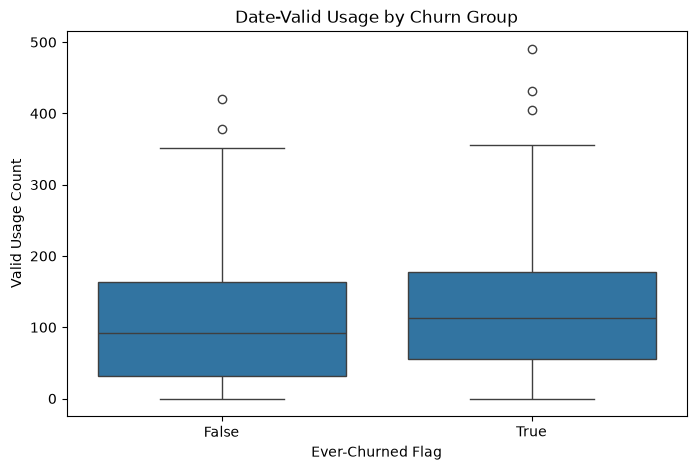

In [53]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="churn_flag",
    y="valid_usage_count"
)

plt.title("Date-Valid Usage by Churn Group")
plt.xlabel("Ever-Churned Flag")
plt.ylabel("Valid Usage Count")
plt.show()

## 7. Support experience

Compare ticket volume, escalations, satisfaction, and resolution time across churn groups. Tickets before signup remain a data-quality limitation.

Satisfaction below is an average of account-level averages, not a ticket-weighted satisfaction score. Missing ratings are not treated as zero.

In [54]:
support_summary = (
    df.groupby("churn_flag")
    .agg(
        accounts=("account_id", "count"),
        avg_tickets=("ticket_count", "mean"),
        avg_escalations=("escalation_count", "mean"),
        avg_satisfaction=("avg_valid_satisfaction", "mean"),
        accounts_with_satisfaction=("avg_valid_satisfaction", "count"),
        avg_resolution_hours=("avg_valid_resolution_hours", "mean")
    )
    .round(2)
)

support_summary.index = support_summary.index.map({
    0: "Never Flagged",
    1: "Ever Churned"
})

display(support_summary)

,accounts,avg_tickets,avg_escalations,avg_satisfaction,accounts_with_satisfaction,avg_resolution_hours
churn_flag,,,,,,
NaN,390,4.02,0.18,3.94,230,36.52
NaN,110,3.93,0.22,4.03,76,35.64


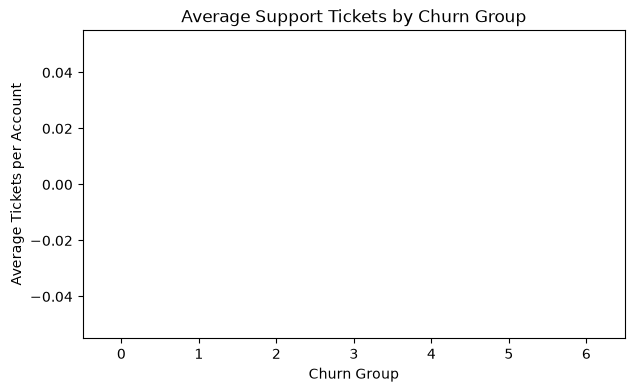

In [55]:
plt.figure(figsize=(7, 4))

sns.barplot(
    data=support_summary.reset_index(),
    x="churn_flag",
    y="avg_tickets"
)

plt.title("Average Support Tickets by Churn Group")
plt.xlabel("Churn Group")
plt.ylabel("Average Tickets per Account")
plt.show()

## 8. Churn event history

Compare account churn labels with recorded churn events. Event history is a separate historical signal; it should not overwrite churn_flag.

In [56]:
df["has_churn_event"] = df["event_count"] > 0

churn_event_summary = pd.crosstab(
    df["churn_flag"],
    df["has_churn_event"]
)

display(churn_event_summary)

has_churn_event,False,True
churn_flag,,
False,113,277
True,35,75


## 9. Key Findings
### Customer Segments
- DevTools has the highest ever-churned percentage (30.97%, 35 of 113 accounts); Cybersecurity has the lowest (16.00%, 16 of 100).
- Plan tiers have very similar ever-churned percentages (approximately 22%). These differences are descriptive and do not imply causation.

### Data Quality Limitations
- Only 5,568 of 25,000 usage records (22.27%) pass the signup and subscription-date rules.
Engagement comparisons are sensitive to limited coverage.
- Account churn labels disagree with the presence of churn-event history. The source account flag remains the definition for segment comparisons.

### Remaining Interpretation
Review the subscription, engagement, account-size, and support outputs before adding further findings or recommendations. Do not assume differences are meaningful without considering group sizes and coverage.



## 10. Export for Power BI
Export the account-level dataset for dashboard development. Each row represents one account; the original SQL tables remain unchanged.

In [57]:
from pathlib import Path

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

dashboard_df = df.copy()
dashboard_df.to_csv(output_dir / "ravenstack_account_360.csv", index=False)

print("Dataset exported successfully.")

Dataset exported successfully.
